# 2. Crowding

**Question.** Once the neighbours competing for the same clinic or school are counted, how much service is there per resident (RQ3, measure M3)?

**Method.** The enhanced two-step floating catchment area (E2SFCA):

1. Each service's supply is divided by the people within 15 minutes of it, each weighted by a Gaussian decay that falls from 1 at the door to 0 at 15 minutes (1,050 m).
2. Each home adds up those ratios over the services within 15 minutes, with the same weights.

- **Supply** is 1 per service, except public schools, which weigh their DepEd 2015 enrolment, so the school score is pupils' places per 10,000 residents. There is no hospital bed count (the DOH registry cannot be exported), so hospitals count 1 each, as the design's fallback says.
- **Demand** is every Metro Manila resident; people just outside Metro Manila are not counted, so services near its edge look less crowded than they are.
- Transit has no supply to share, so it has no M3.
- Scores are per 10,000 residents; the Metro Manila mean is the yardstick.

In [1]:
import sys
from pathlib import Path

# The notebooks import their logic from src/: the shared helpers and the analysis functions.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shared").is_dir())
for folder in ("src/shared", "src/03_analyse"):
    sys.path.insert(0, str(ROOT / folder))

import charts
import measures
import pandas as pd
from common import TABLES
from IPython.display import Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
AREAS = measures.STUDY + ["Metro Manila"]
m = pd.read_csv(TABLES / "measures.csv")

In [2]:
m[(m.measure == "M3") & m.stat.isin(["mean_per_10k", "median_per_10k"]) & m.area.isin(AREAS)].pivot_table(
    index=["category", "stat"], columns="area", values="value", sort=False
)[AREAS].round(2)

area                              Barangay 136  Loyola Heights   Oranbo  Metro Manila
category          stat                                                               
food_retail       median_per_10k          1.71           13.05    13.71          3.98
                  mean_per_10k            1.87           15.51    12.82          5.75
palengke          median_per_10k          0.08            1.11     2.18          0.22
                  mean_per_10k            0.09            1.19     1.95          0.38
pharmacy          median_per_10k          1.52            2.19     7.09          1.77
                  mean_per_10k            1.58            3.48     6.61          2.39
primary_care      median_per_10k          2.25            2.94     4.03          1.89
                  mean_per_10k            2.18            3.15     4.18          2.64
hospital          median_per_10k          0.18            0.00     0.60          0.18
                  mean_per_10k            0.17            0.27     0.62          0.42
public_elementary median_per_10k       2187.54            0.00  1126.21        739.34
                  mean_per_10k         2228.55          145.73   949.77        943.39
public_high       median_per_10k       1384.19            0.00     0.00         83.38
                  mean_per_10k         1398.67          190.60     0.83        474.31
open_space        median_per_10k          0.02            1.65     1.66          0.13
                  mean_per_10k            0.02            3.61     1.72          0.51

In [3]:
m3 = m[(m.measure == "M3") & (m.stat == "mean_per_10k")].pivot_table(
    index="category", columns="area", values="value", sort=False
)
(m3[measures.STUDY].div(m3["Metro Manila"], axis=0)).round(2)

area,Barangay 136,Loyola Heights,Oranbo
category,,,
food_retail,0.33,2.70,2.23
palengke,0.23,3.17,5.19
pharmacy,0.66,1.46,2.76
primary_care,0.83,1.19,1.58
hospital,0.41,0.65,1.48
public_elementary,2.36,0.15,1.01
public_high,2.95,0.40,0.00
open_space,0.05,7.07,3.37


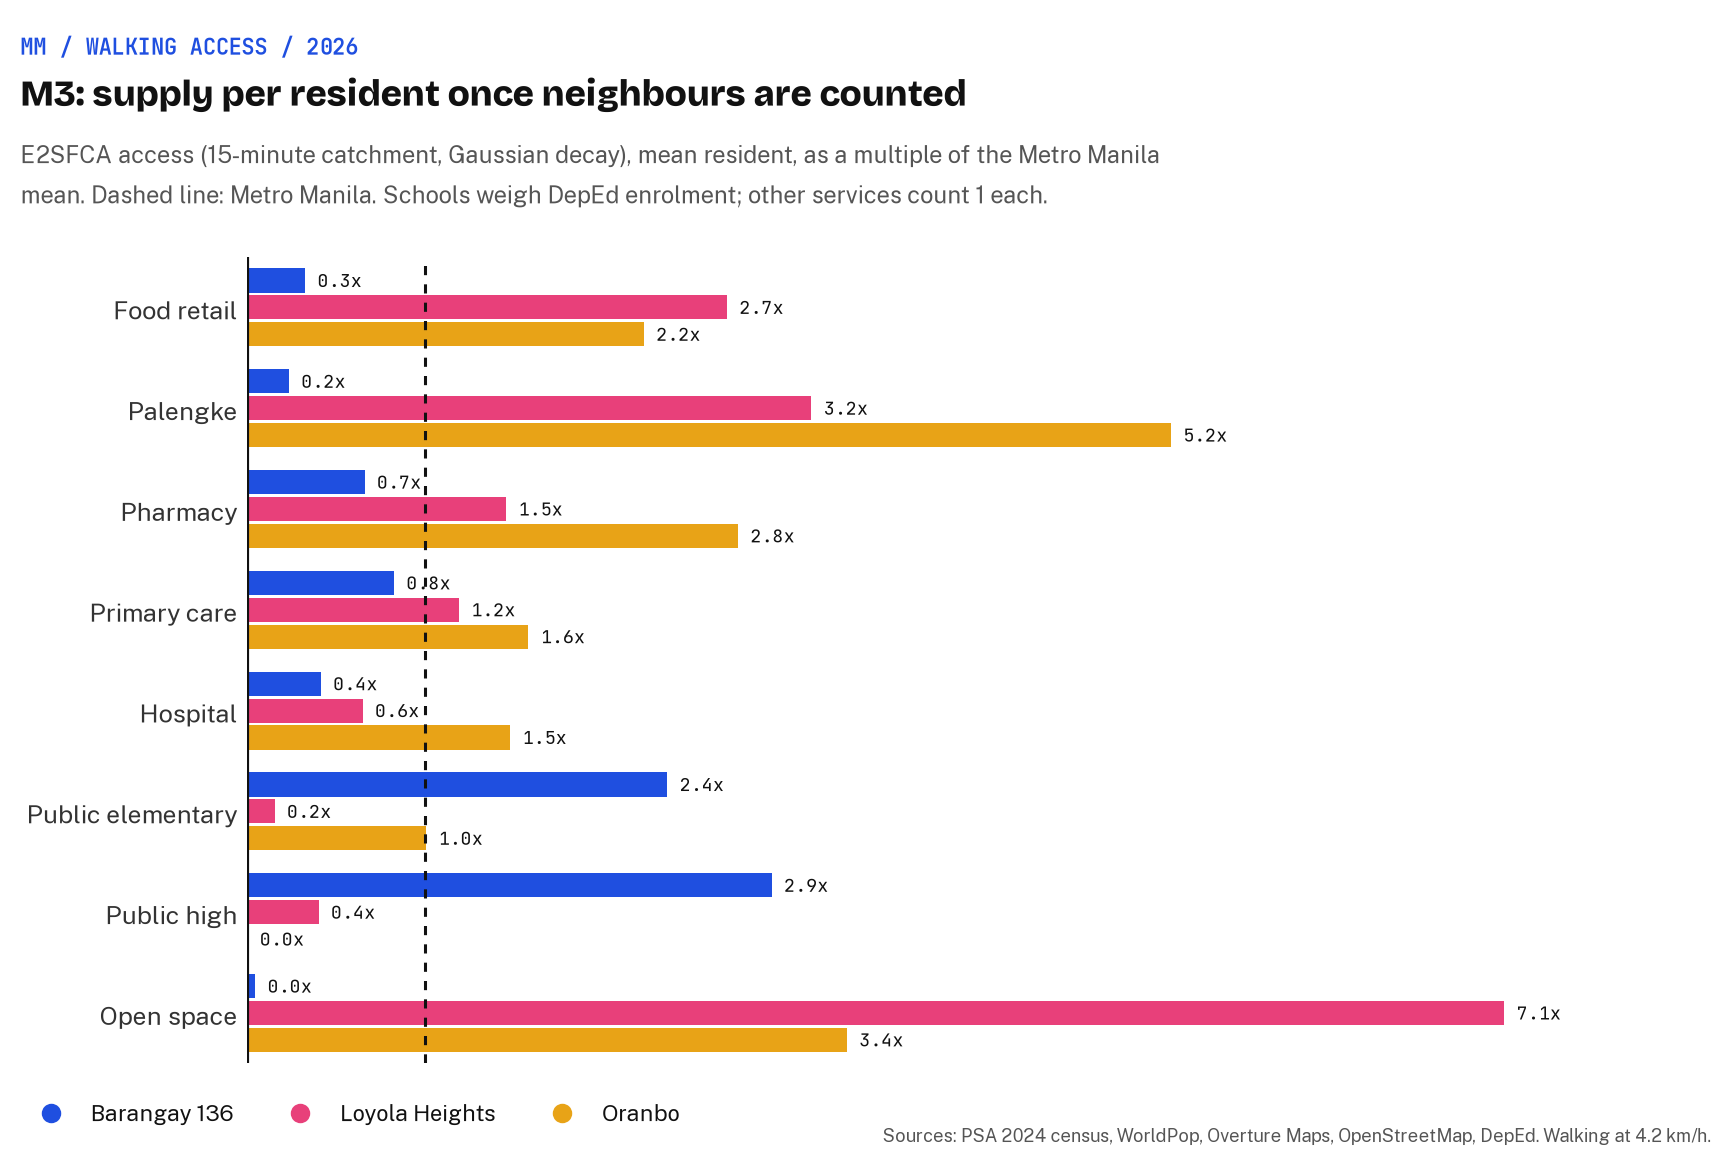

In [4]:
Image(charts.m3_chart(m))

**Reading.** Once neighbours are counted the picture changes for the densest place.

- **Barangay 136** sits in the most crowded streets, so its mean resident has a third of Metro Manila's food supply per person (0.33x), two thirds of its pharmacy supply and less than half of its hospital supply (0.41x), although every one of these is a short walk away. Its school supply is the exception: 2.4 times the Metro Manila mean for public elementary places and 3.0 times for public high school places, with large public schools close by.
- **Oranbo** has more supply per resident than Metro Manila for food (2.2 times), the palengke (5.2), pharmacies (2.8), primary care (1.6), hospitals (1.5) and open space (3.4), the Metro Manila level for public elementary places, and almost no public high school places within reach.
- **Loyola Heights** is above Metro Manila for food, the palengke, pharmacies, clinics and open space (7.1 times), but has 0.15 times the Metro Manila elementary school supply and 0.65 times its hospital supply.

Hospitals count one each (there are no bed counts), so the hospital figures measure facilities per person, not capacity.